# 02 Forecasting: baselines and linear models
Now we'll carry out day-ahead forecasts of the half-hourly price at Mt Roskill (`ROS1101`), scored on the validation year (Jul 2024 to Jun 2025) using walk-forward validation.

| Model | How it predicts price on day D, period t |
|---|---|
| Model 0 Naive | Yesterday's price, same period |
| Model 1 Weekly naive | Last week's price, same period |
| Model 2a Linear (least squares) | Linear model minimising squared error |
| Model 2b Linear (absolute error) | Linear model minimising absolute error: quantile regression at the median, solved as an LP |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, QuantileRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
feats = pd.read_parquet("../data/processed/features.parquet")

# Validation year: used to compare models (the test year Jul 2025 to Jun 2026 stays untouched until Day 3)
VAL_START, VAL_END = "2024-07", "2025-06"

# Feature groups
LAGS = ["lag_1d", "lag_2d", "lag_7d", "tp_mean_7d", "prev_day_mean", "prev_day_max"]
CALENDAR = ["tp", "dow", "month", "is_weekend", "is_holiday"]
WEATHER = ["akl_temp", "mnw_wind"]
FEATURES = LAGS + CALENDAR + WEATHER

# Keep only rows where every feature exists, so all models are scored on identical rows
df = feats.dropna(subset=FEATURES).reset_index(drop=True)
print(f"Rows usable for modelling: {len(df):,} of {len(feats):,}")

Rows usable for modelling: 59,424 of 60,912


## Scoring
- **MAE**: mean absolute error in \$/MWh. The main metric, since spikes would dominate squared-error metrics.
- **RMSE**: punishes big misses more; reported for comparison.
- **Spearman**: for each day, does the forecast rank the 48 periods in the right order (cheapest to dearest)? 1 = perfect, 0 = random. This is what the battery actually needs.

In [3]:
def evaluate(actual, pred, dates):
    """Score one model: MAE, RMSE, and average within-day Spearman rank correlation."""
    err = actual - pred
    table = pd.DataFrame({"actual": actual, "pred": pred, "date": dates})
    # For each day: does the forecast rank the 48 periods in the right order? (1 = perfect, 0 = random)
    spearman = (table.groupby("date")
                     .apply(lambda d: d["actual"].corr(d["pred"], method="spearman"), include_groups=False)
                     .mean())
    return pd.Series({"MAE": err.abs().mean(),               # average absolute error, $/MWh
                      "RMSE": np.sqrt((err ** 2).mean()),     # punishes big misses more
                      "Spearman": spearman})

## Walk-forward validation
At the start of each validation month, the model is retrained on all data before that month, then predicts that month. This mimics real use and guarantees the model never trains on the future.

In [4]:
def walk_forward(fit_predict, start=VAL_START, end=VAL_END):
    """Retrain at the start of each month on all earlier data, then predict that month."""
    def one_month(month):
        train = df[df["date"] < month.start_time]               # everything before this month
        test = df[df["date"].dt.to_period("M") == month]        # just this month
        result = pd.Series(fit_predict(train, test), index=test.index)
        print(f"  {month.strftime('%m/%Y')} done")              # progress update
        return result
    # map() runs one_month for each month; concat() joins the 12 months of predictions
    return pd.concat(map(one_month, pd.period_range(start, end, freq="M")))

## Models
Model 2a and Model 2b use identical features and structure; only the loss function differs, so any gap between them is purely the effect of squared vs absolute error.

In [5]:
# Model 0: tomorrow's price = today's price, same trading period (no training needed)
def naive(train, test):
    return test["lag_1d"]

# Model 1: tomorrow's price = same day last week, same trading period (captures weekday/weekend)
def weekly_naive(train, test):
    return test["lag_7d"]


def linear_pipeline(regressor):
    """Prepare the features for a linear model, then fit `regressor`.
    - tp, dow, month are categories: one-hot encode them. drop="first" removes one
      column per category, so the columns aren't perfectly collinear with the intercept
    - lags and weather are numbers on different scales: standardise them (where mean 0, std 1)
    - is_holiday is already 0/1: pass it through. (is_weekend is left out because the
      dow columns already contain that information.)
    """
    return make_pipeline(
        ColumnTransformer([
            ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"), ["tp", "dow", "month"]),
            ("scale", StandardScaler(), LAGS + WEATHER),
            ("holiday", "passthrough", ["is_holiday"]),
        ]),
        regressor,
    )


def make_fit_predict(model):
    """Wrap a model so walk_forward can call it: fit on train, predict test."""
    def fit_predict(train, test):
        model.fit(train[FEATURES], train["price"])
        return model.predict(test[FEATURES])
    return fit_predict


# Model 2a: ordinary least squares, minimising the sum of squared errors
ols_model = linear_pipeline(LinearRegression())
# Model 2b: quantile regression at the median, minimising the sum of absolute errors (solved as an LP by HiGHS)
lad_model = linear_pipeline(QuantileRegressor(quantile=0.5, alpha=0, solver="highs"))

# Run all four through walk-forward validation
preds = pd.DataFrame({
    "Model 0 Naive (yesterday)": walk_forward(naive),
    "Model 1 Weekly naive (last week)": walk_forward(weekly_naive),
    "Model 2a Linear (least squares)": walk_forward(make_fit_predict(ols_model)),
    "Model 2b Linear (absolute error)": walk_forward(make_fit_predict(lad_model)),
})
val = df.loc[preds.index]       # the validation rows, lined up with the predictions

  07/2024 done
  08/2024 done
  09/2024 done
  10/2024 done
  11/2024 done
  12/2024 done
  01/2025 done
  02/2025 done
  03/2025 done
  04/2025 done
  05/2025 done
  06/2025 done
  07/2024 done
  08/2024 done
  09/2024 done
  10/2024 done
  11/2024 done
  12/2024 done
  01/2025 done
  02/2025 done
  03/2025 done
  04/2025 done
  05/2025 done
  06/2025 done
  07/2024 done
  08/2024 done
  09/2024 done
  10/2024 done
  11/2024 done
  12/2024 done
  01/2025 done
  02/2025 done
  03/2025 done
  04/2025 done
  05/2025 done
  06/2025 done
  07/2024 done
  08/2024 done
  09/2024 done
  10/2024 done
  11/2024 done
  12/2024 done
  01/2025 done
  02/2025 done
  03/2025 done
  04/2025 done
  05/2025 done
  06/2025 done


In [8]:
preds.to_parquet("../results/validation_predictions.parquet")

## Results: validation year (Jul 2024 to Jun 2025)

In [6]:
# Score each model column; .T flips the table so models are rows
results = preds.apply(lambda p: evaluate(val["price"], p, val["date"])).T.round(2)
results.to_csv("../results/validation_baselines.csv")
results

,MAE,RMSE,Spearman
Model 0 Naive (yesterday),56.90,124.33,0.38
Model 1 Weekly naive (last week),89.18,160.11,0.32
Model 2a Linear (least squares),49.93,95.65,0.52
Model 2b Linear (absolute error),48.44,95.79,0.52


## Forecast vs actual: one week
A week from the August 2024 price spike, the hardest period in the validation year.

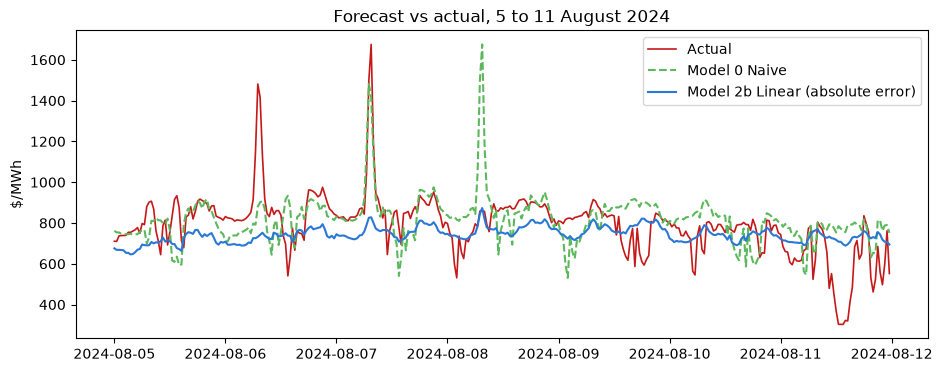

In [12]:
BLUE, GREEN, RED = "#2a78d6", "#5cb85c", "#c51919"

# One validation week during the August 2024 price spike
week = val[(val["date"] >= "2024-08-05") & (val["date"] < "2024-08-12")].index

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(val.loc[week, "time_nz"], val.loc[week, "price"], color=RED, linewidth=1.2, label="Actual")
ax.plot(val.loc[week, "time_nz"], preds.loc[week, "Model 0 Naive (yesterday)"], color=GREEN, linestyle="--", label="Model 0 Naive")
ax.plot(val.loc[week, "time_nz"], preds.loc[week, "Model 2b Linear (absolute error)"], color=BLUE, label="Model 2b Linear (absolute error)")
ax.set_title("Forecast vs actual, 5 to 11 August 2024")
ax.set_ylabel("$/MWh")
ax.legend()
fig.savefig("../results/figures/06_baseline_week.png", dpi=150, bbox_inches="tight")

In [10]:
preds.columns

Index(['Model 0 Naive (yesterday)', 'Model 1 Weekly naive (last week)',
       'Model 2a Linear (least squares)', 'Model 2b Linear (absolute error)'],
      dtype='str')